# Reusable experiment plans and sky/ground batteries

Setup is in [Tutorial.ipynb](Tutorial.ipynb). This replaces the old ReCirq-specific walkthrough.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import cirq
from pathlib import Path
import tempfile

from cirq_sic.measurements import Measurement, sic_povm, wh_measurement
from cirq_sic.workflow import (
    Experiment, ExperimentResult, tomography_experiment, entropy_experiment,
    wh_entropy_experiment, sky_ground_experiment, triple_product_experiment,
    compile_circuit,
)
from cirq_sic.analysis import stabilizer_renyi_entropy, born_rule_diagnostics
from cirq_sic.triples import triple_products, triple_product_state_space, sic_state_constraints

rng = np.random.default_rng(2026)
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
print('Cirq', cirq.__version__)

Cirq 1.3.0


In [2]:
d = 3
sic = sic_povm(d)
psi = np.array([1, 1j, -0.4 + 0.2j], dtype=complex)
psi /= np.linalg.norm(psi)
experiment = tomography_experiment(psi, sic)
exact = experiment.simulate()
sampled = experiment.run(repetitions=12000, seed=2026)

print(sic)
print('system / measurement ancillas:', sic.num_system_qubits, sic.num_ancilla_qubits)
print('qubit order:', experiment.circuits[0].qubit_order)
print('ideal leakage:', exact['measurement'].leakage)
assert np.allclose(exact['measurement'].valid, sic.probabilities(psi), atol=1e-10)
assert exact['measurement'].leakage < 1e-12
print(experiment.circuits[0].circuit.to_text_diagram())

Measurement(name='SIC-POVM', dimension=3, num_outcomes=9)
system / measurement ancillas: 2 2
qubit order: (cirq.LineQubit(0), cirq.LineQubit(1), cirq.LineQubit(2), cirq.LineQubit(3))
ideal leakage: 0.0
0: ───Prepare[1]───SIC-POVM[1]───M('outcome')───
      │            │             │
1: ───Prepare[2]───SIC-POVM[2]───M──────────────
                   │             │
2: ────────────────SIC-POVM[3]───M──────────────
                   │             │
3: ────────────────SIC-POVM[4]───M──────────────


In [3]:
rho_true = np.outer(psi, psi.conj())
raw = experiment.analyze(sampled)
physical = experiment.analyze(sampled, physical=True)
assert np.allclose(experiment.analyze(exact)['density_matrix'], rho_true, atol=1e-8)
print('Linear-inversion minimum eigenvalue:', raw['minimum_eigenvalue'])
print('Projected minimum eigenvalue:', physical['minimum_eigenvalue'])
print('Reconstruction Frobenius error:', np.linalg.norm(physical['density_matrix'] - rho_true))

Linear-inversion minimum eigenvalue: -0.01493653761732944
Projected minimum eigenvalue: 2.818902889985999e-17
Reconstruction Frobenius error: 0.014916398747555777


The analysis uses observed probabilities, not the state used to build the
preparation circuit. Linear inversion enforces Hermiticity and trace one but may
produce negative eigenvalues with finite shots. `physical=True` projects the
estimate onto the trace-one positive cone in Frobenius norm; it is not maximum
likelihood. The plotted errors are marginal binomial plug-in standard errors,
not simultaneous confidence bands. The outcomes are correlated.

### Save a circuit plan and its data independently

Artifacts are versioned, inspectable JSON containing standard Cirq circuits,
explicit qubit layouts, complex numeric analysis inputs, counts, and execution
metadata. They do not depend on ReCirq or pickle.

In [4]:
artifact_directory = tempfile.TemporaryDirectory(prefix='cirq-sic-tutorial-')
artifact_path = Path(artifact_directory.name)
experiment.save(artifact_path / 'qutrit-plan.json')
sampled.save(artifact_path / 'qutrit-data.json')
restored = Experiment.load(artifact_path / 'qutrit-plan.json')
restored_data = ExperimentResult.load(artifact_path / 'qutrit-data.json')
assert np.array_equal(restored_data['measurement'].counts, sampled['measurement'].counts)
assert np.allclose(restored.analyze(restored_data, physical=True)['density_matrix'],
                   physical['density_matrix'])
print('Saved and reloaded', len(restored.circuits), 'circuit with all counts.')

Saved and reloaded 1 circuit with all counts.


In [5]:
qubit_sic = sic_povm(2)
rho_mixed = np.array([[.6, .1j], [-.1j, .4]])

## 3. Sky/ground consistency across experiments

For each input state, measure sky probabilities $p_i$ and direct ground
probabilities $q_j$. Independently prepare every normalized reference state
$\sigma_i$ to calibrate $C_{ji}=\mathrm{Tr}(G_j\sigma_i)$ and
$P_{ki}=\mathrm{Tr}(E_k\sigma_i)$. The consistency prediction is

$$q=C P^{-1}p.$$

For an ideal SIC, $P^{-1}=(d+1)I-J/d$, giving the QBist form
$q_j=\sum_i[(d+1)p_i-1/d]C_{ji}$. The experiment measures the reference table
rather than assuming it is ideal. A singular reference is rejected. Ill
conditioning amplifies finite-shot noise and is reported.

Circuits: 14
Reference condition number: 3.012259860896905
Largest absolute residual: 0.024883927128052763


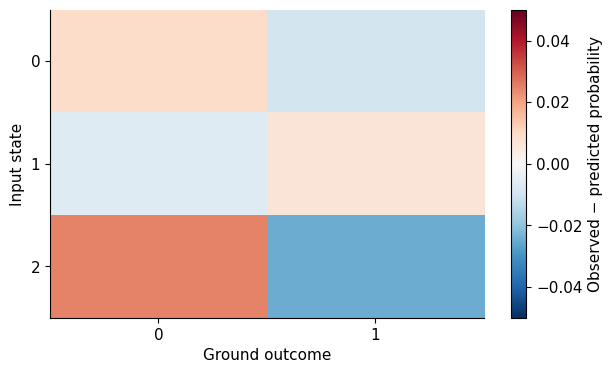

In [6]:
states = [np.array([1., 0.]), np.array([1, 1j])/np.sqrt(2), rho_mixed]
sky_plan = sky_ground_experiment(states, qubit_sic)
sky_exact = sky_plan.analyze(sky_plan.simulate())
sky_sampled = sky_plan.analyze(sky_plan.run(repetitions=10000, seed=35))
assert np.max(np.abs(sky_exact['residual'])) < 1e-9
print('Circuits:', len(sky_plan.circuits))
print('Reference condition number:', sky_sampled['reference_condition'])
print('Largest absolute residual:', np.max(sky_sampled['max_abs_error']))
fig, ax = plt.subplots()
im = ax.imshow(sky_sampled['residual'], cmap='RdBu_r', vmin=-.05, vmax=.05, aspect='auto')
ax.set(xlabel='Ground outcome', ylabel='Input state', xticks=[0, 1], yticks=[0, 1, 2])
fig.colorbar(im, ax=ax, label='Observed − predicted probability')
plt.show()

A consistency residual is a hardware diagnostic, not by itself evidence
against the Born rule. Preparation drift, gate error, leakage and sampling noise
can all matter. An internally consistent noisy device can still satisfy this
relation. To demonstrate sensitivity, the next cell deliberately changes only
the *direct ground* experiments. All other calibration and sky experiments stay
ideal; the mismatch must appear in the residual.

In [7]:
from cirq_sic.workflow import CircuitSpec
changed = []
for spec in sky_plan.circuits:
    circuit = spec.circuit
    if spec.name.startswith('ground/'):
        body = cirq.drop_terminal_measurements(circuit)
        circuit = body + cirq.Circuit(cirq.bit_flip(.12).on(spec.measured_qubits[0]),
                                     cirq.measure(*spec.measured_qubits, key=spec.key))
    changed.append(CircuitSpec(spec.name, circuit, spec.qubit_order, spec.measured_qubits,
                               spec.key, spec.num_outcomes, spec.metadata))
drifting_plan = Experiment(changed, sky_plan.name, sky_plan.metadata, sky_plan.arrays)
drift = drifting_plan.analyze(drifting_plan.simulate())
print('Mismatch with ground-only bit-flip channel:', drift['max_abs_error'])
assert drift['max_abs_error'][0] > .1

Mismatch with ground-only bit-flip channel: [1.20000000e-01 2.22044605e-16 2.40000000e-02]


## 5. Compile, inspect, and iterate

The mathematical construction contains dense unitary gates. `compile_circuit`
synthesizes one- and two-qubit operations and targets CZ gates by default. The
synthesis uses a stable Schur-based decomposition for degenerate padded blocks.
This is a correctness reference, not a low-depth SIC synthesis algorithm.
A SIC dilation stores $O(d^4)$ complex numbers and dense completion costs roughly
$O(d^6)$; hardware gate counts grow quickly. Arbitrary dimension means the
encoding has no power-of-two restriction, not that every dimension is affordable.

Gate synthesis does not route or validate against a particular device topology.
After your own placement/routing, supply a `cirq.Sampler` to `plan.run(...)`.
If routing changes qubits, construct updated `CircuitSpec` layouts explicitly.
Do not reuse the old output order. No cloud submission is performed here.